In [7]:
import numpy as np

rng = np.random.default_rng(42)

reference  = rng.normal(loc=0.0, scale=1.0, size=10_000)  # training-time feature
no_drift   = rng.normal(loc=0.0, scale=1.0, size=10_000)  # same distribution
mild_drift = rng.normal(loc=0.3, scale=1.0, size=10_000)  # small mean shift
big_drift  = rng.normal(loc=1.0, scale=1.5, size=10_000)  # shifted mean and wider spread


In [8]:
# Split the feature into bins, then compare the share of rows in each bin, reference (e) vs current (a):
# PSI = Σ (a − e) × ln(a / e)
# Each bin adds a penalty that grows with how far its share moved. 
# Rule of thumb: below 0.1 stable, 0.1 to 0.25 moderate drift, above 0.25 significant drift.

def psi(reference, current, bins=10, eps=1e-6):
    edges = np.quantile(reference, np.linspace(0, 1, bins + 1)) # edges of each bin
    edges[0], edges[-1] = -np.inf, np.inf

    e = np.histogram(reference, bins=edges)[0] / len(reference) # Share of rows in each bin as edges
    a = np.histogram(current, bins=edges)[0] / len(current) # share of rows in each bin of current dist

    e = np.clip(e, eps, None)
    a = np.clip(a, eps, None)
    return np.sum((a - e) * np.log(a / e))

for name, cur in [("no_drift", no_drift), ("mild_drift", mild_drift), ("big_drift", big_drift)]:
    print(name, psi(reference, cur))


no_drift 0.0021992269277573495
mild_drift 0.10101579086277795
big_drift 0.6798786995089124


In [9]:
# CDF (cumulative distribution function) at a value x = the fraction of data that is ≤ x. 
# It always starts at 0, rises, and ends at 1.
# It jumps up at each data point and stays flat in between. That staircase is called the empirical CDF.


def ks_stat(reference, current):
    ref_sorted = np.sort(reference)
    cur_sorted = np.sort(current)
    points = np.concatenate([ref_sorted, cur_sorted])

    # np.searchsorted([1, 2, 3, 4, 5], 1, side='right') -- no of values below or equal point. 
    cdf_ref = np.searchsorted(ref_sorted, points, side="right") / len(reference)
    cdf_cur = np.searchsorted(cur_sorted, points, side="right") / len(current)
    return np.max(np.abs(cdf_ref - cdf_cur))

for name, cur in [("no_drift", no_drift), ("mild_drift", mild_drift), ("big_drift", big_drift)]:
    print(name, ks_stat(reference, cur))

from scipy.stats import ks_2samp
print(ks_2samp(reference, big_drift))   # statistic should match yours

no_drift 0.016100000000000003
mild_drift 0.13540000000000002
big_drift 0.34659999999999996
KstestResult(statistic=0.3466, pvalue=0.0, statistic_location=0.8697611871649563, statistic_sign=1)


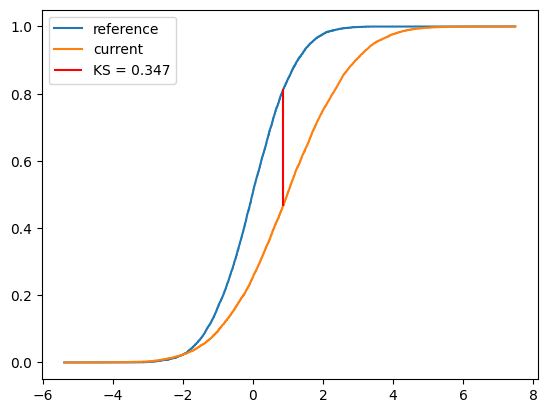

In [10]:
import matplotlib.pyplot as plt

ref_s, cur_s = np.sort(reference), np.sort(big_drift)
pts = np.sort(np.concatenate([ref_s, cur_s]))
c1 = np.searchsorted(ref_s, pts, side="right") / len(ref_s)
c2 = np.searchsorted(cur_s, pts, side="right") / len(cur_s)
i = np.argmax(np.abs(c1 - c2))

plt.step(pts, c1, label="reference")
plt.step(pts, c2, label="current")
plt.vlines(pts[i], c1[i], c2[i], colors="red", label=f"KS = {abs(c1[i] - c2[i]):.3f}")
plt.legend()
plt.show()



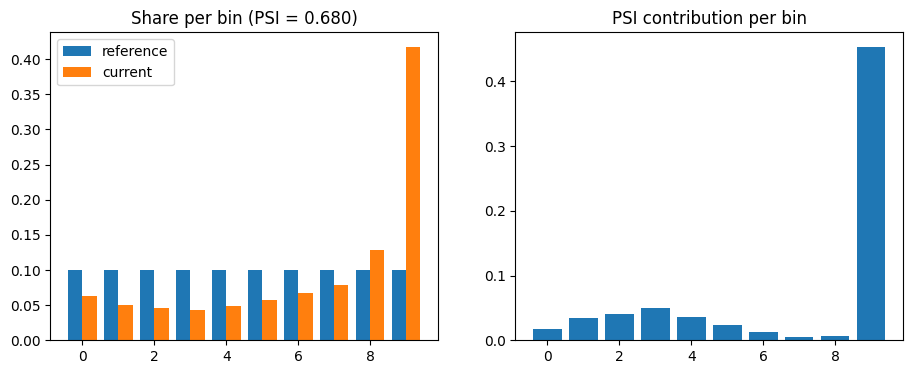

In [11]:
import matplotlib.pyplot as plt

def psi_bins(reference, current, bins=10, eps=1e-6):
    edges = np.quantile(reference, np.linspace(0, 1, bins + 1))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.clip(np.histogram(reference, bins=edges)[0] / len(reference), eps, None)
    a = np.clip(np.histogram(current, bins=edges)[0] / len(current), eps, None)
    return e, a, (a - e) * np.log(a / e)

e, a, contrib = psi_bins(reference, big_drift)
x = np.arange(len(e))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(x - 0.2, e, 0.4, label="reference")
ax[0].bar(x + 0.2, a, 0.4, label="current")
ax[0].set_title(f"Share per bin (PSI = {contrib.sum():.3f})")
ax[0].legend()
ax[1].bar(x, contrib)
ax[1].set_title("PSI contribution per bin")
plt.show()


In [12]:
ref_share = np.array([0.6, 0.3, 0.1])
observed  = np.array([500, 350, 150])

expected = ref_share * observed.sum()
chi2 = np.sum((observed - expected) ** 2 / expected)
print(chi2)   # 50.0


50.0


In [13]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

rng = np.random.default_rng(42)

def make_data(n, amount_mean=100, p=(0.6, 0.3, 0.1)):
    df = pd.DataFrame({
        "amount": rng.normal(amount_mean, 20, n),
        "age": rng.normal(35, 8, n),
        "channel": rng.choice(["card", "upi", "cash"], n, p=p),
    })
    logit = (df["amount"] - 130) / 10
    df["y"] = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)
    return df

train = make_data(10_000)
model = LogisticRegression().fit(train[["amount", "age"]], train["y"])
train["score"] = model.predict_proba(train[["amount", "age"]])[:, 1]


In [17]:
batches = {}
for w in range(1, 9):
    d = max(0, w - 2)                     # weeks 1-2 clean, drift grows after
    upi = 0.3 + 0.04 * d
    b = make_data(2_000, amount_mean=100 + 4 * d, p=(0.9 - upi, upi, 0.1))
    b["score"] = model.predict_proba(b[["amount", "age"]])[:, 1]
    batches[w] = b

# Drift can be sudden (a pipeline bug, a new product) or gradual (seasonality, customer mix). Gradual drift is harder, because week-over-week changes look small. That's why you compare against the fixed reference, not the previous week.


In [ ]:
from scipy.stats import ks_2samp, chisquare

cats = ["card", "upi", "cash"]
ref_share = train["channel"].value_counts(normalize=True).reindex(cats).values

rows = []
for w, b in batches.items():
    obs = b["channel"].value_counts().reindex(cats, fill_value=0).values
    rows.append({
        "week": w,
        "csi_amount": psi(train["amount"], b["amount"]),
        "csi_age": psi(train["age"], b["age"]),
        "ks_amount": ks_2samp(train["amount"], b["amount"]).statistic,
        "chi2_p_channel": chisquare(obs, ref_share * obs.sum()).pvalue,
        "psi_score": psi(train["score"], b["score"]),
    })

report = pd.DataFrame(rows).set_index("week")
report

# Feature drift does not always mean score drift. A feature the model barely uses can drift without moving the output, while a small drift in a heavily weighted feature moves it a lot. Monitor both, and prioritize alerts by feature importance

,csi_amount,csi_age,ks_amount,chi2_p_channel,psi_score
week,,,,,
1,0.003286,0.003130,0.0167,5.314554e-01,0.003984
2,0.005140,0.004392,0.0288,8.702726e-01,0.004868
3,0.050938,0.008284,0.0895,6.203539e-06,0.051014
4,0.133137,0.005278,0.1604,3.518684e-09,0.132473
5,0.356512,0.002187,0.2587,4.049091e-20,0.356811
6,0.545472,0.006160,0.3007,2.312583e-60,0.545439
7,0.939959,0.005536,0.3914,6.196154e-93,0.939106
8,1.354822,0.002272,0.4691,1.354878e-118,1.364252


In [18]:
level = lambda s: np.select([s > 0.25, s > 0.1], ["ALERT", "WARN"], "ok")

status = pd.DataFrame(
    {c: level(report[c]) for c in ["csi_amount", "csi_age", "psi_score"]},
    index=report.index,
)
status["channel"] = np.where(report["chi2_p_channel"] < 0.05, "ALERT", "ok")
status


,csi_amount,csi_age,psi_score,channel
week,,,,
1,ok,ok,ok,ok
2,ok,ok,ok,ok
3,ok,ok,ok,ALERT
4,WARN,ok,WARN,ALERT
5,ALERT,ok,ALERT,ALERT
6,ALERT,ok,ALERT,ALERT
7,ALERT,ok,ALERT,ALERT
8,ALERT,ok,ALERT,ALERT


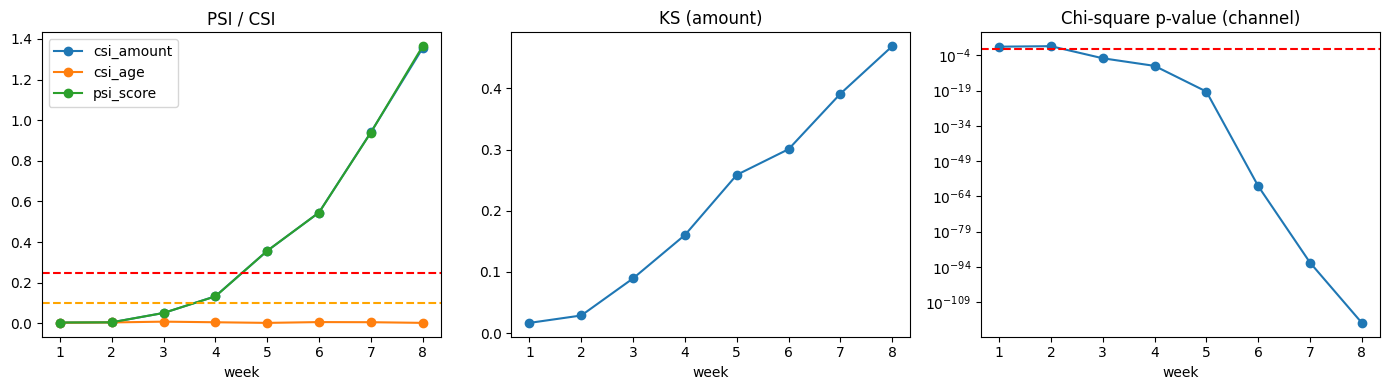

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))

report[["csi_amount", "csi_age", "psi_score"]].plot(ax=ax[0], marker="o", title="PSI / CSI")
ax[0].axhline(0.1, ls="--", c="orange")
ax[0].axhline(0.25, ls="--", c="red")

report["ks_amount"].plot(ax=ax[1], marker="o", title="KS (amount)")

report["chi2_p_channel"].plot(ax=ax[2], marker="o", title="Chi-square p-value (channel)")
ax[2].axhline(0.05, ls="--", c="red")
ax[2].set_yscale("log")

plt.tight_layout()
plt.show()


In [20]:
from sklearn.metrics import roc_auc_score, recall_score

thr = np.quantile(train["score"], 0.9)   # flag the top 10% of training scores

perf = []
for w, b in batches.items():
    perf.append({
        "week": w,
        "auc": roc_auc_score(b["y"], b["score"]),
        "recall": recall_score(b["y"], b["score"] >= thr),
        "fraud_rate": b["y"].mean(),
    })
perf = pd.DataFrame(perf).set_index("week")
perf

# In production, week w labels arrive weeks later (chargebacks, repayment). So drift metrics are the early warning, performance metrics are the confirmation, and you need both.

,auc,recall,fraud_rate
week,,,
1,0.862346,0.452282,0.1205
2,0.884547,0.469925,0.1330
3,0.873646,0.533123,0.1585
4,0.877676,0.586118,0.1945
5,0.857010,0.618367,0.2450
6,0.867478,0.715532,0.2865
7,0.866761,0.743954,0.3515
8,0.857271,0.769890,0.4085


In [22]:
def make_concept_drift(n):
    df = make_data(n)                                    # same input distributions as training
    logit = (df["age"] - 45) / 4                         # fraud is now driven by age, not amount
    df["y"] = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)
    df["score"] = model.predict_proba(df[["amount", "age"]])[:, 1]
    return df

cd = make_concept_drift(2_000)

print("csi_amount", psi(train["amount"], cd["amount"]))
print("csi_age   ", psi(train["age"], cd["age"]))
print("psi_score ", psi(train["score"], cd["score"]))
print("auc       ", roc_auc_score(cd["y"], cd["score"]))
print("recall    ", recall_score(cd["y"], cd["score"] >= thr))

# Concept drift can't be seen from X alone. You only catch it with labels, so delayed-label performance tracking matters most for it. While labels are late, teams use proxies: score distribution shifts, business KPIs (approval rate, complaint volume), and small human-labeled samples.


csi_amount 0.002949745325681681
csi_age    0.007907625479295691
psi_score  0.0026961768616682656
auc        0.4920231912826498
recall     0.10404624277456648
